# Figure 3 Supplement 3: The stopping model captures apparently suboptimal behavior

**A — how well the model predicts each choice, per subject.** y: the correlation
across that subject's trials between the model's probability of a rightward
choice (`get_choice_probabilities`: given the trial's positions up to the key
press and its RT) and the actual choice. x: the model's estimate of the fraction
of that subject's choices that were not driven by the evidence: the mean over
trials of 1 − (1 − P(guess)) × (1 − lapse rate), with P(guess) the posterior
probability that the commit was an early or pure guess
(`get_commit_type_probabilities`) and the fitted lapse rate. Choices are poorly
predicted mainly where the model attributes them to guesses and lapses. All of
the subject's fit trials, without the standard filter; subject-blocks whose
plateau sits at a fit limit are left out (a choice prediction for random
responding is uninformative).

Two features of the direct bound measures look like departures from an ideal
bound-crossing process (both defined in `pigeon.data.get_crossing_diagnostics`,
at the commit step inferred by `get_bounds`):

- **Incongruent choice:** the choice is opposite to the side the pigeon was on
  at the inferred commit (sign of the midpoint of the positions at DT − 1 and
  DT).
- **Premature crossing:** the pigeon had already been at or beyond the measured
  bound on that side before the inferred commit, without the subject
  committing.

**B, C** — the fraction of trials with each feature vs. the measured |bound|,
data (black; mean ± SEM across subjects) and the stopping model (dashed blue;
each subject simulated `SIM_REPS` times from their fit and measured with the
same pipeline). **D** — what produces these trials in the model
(`pigeon.stopping.get_commit_sources`): an early guess (a commit inside the bound; pure guesses, on the first frame, can't pass the DT ≥ 2 filter) instead of a bound crossing; a
lapse (a bound commit with a random choice; lapses on guesses count as guesses); NDT uncertainty (the
pipeline's assumed NDT was not the one that occurred, so it placed the commit at the wrong step); sensory noise (the perceived position crossed the bound but
the on-screen position had not, on that side); measurement error (the pigeon crossed
zero between DT − 1 and DT, so the midpoint used by the measures can fall on
the other side); or the collapsing bound (none of the above: the pigeon had been
farther out earlier, when the bound was still higher). Each simulated trial
gets the first source that applies, in that order.

Columns: OL low-SNR blocks 1–3 (no-penalty, coin-penalty and step-penalty
conditions), as in the other Figure 3 supplements. Trials: those the model was fit to
(`get_stopping_model_trials`: trial_number ≥ 10, with a choice) that pass the standard
filter (`get_good_trial_array`: DT ≥ 2, no wall hit, RT cutoff); raw positions (no bias correction) for both
data and model. All subject-blocks are included in B–D.

In [1]:
import sys
sys.path.insert(0, '..')


import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.data import get_crossing_diagnostics, get_good_trial_array
from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import (CM, FS_INSET, CONDITION_LABELS, DATA_COLOR, GUESS_COLOR, LAPSE_BAR, MODEL_COLOR,
                             SUBJECT_MARKER, add_panel_label, add_row_xlabel, format_p, format_rho, use_figure_style)
from pigeon.stopping import (COMMIT_SOURCES, get_choice_probabilities, get_commit_sources,
                             get_commit_type_probabilities, get_plateau_at_limit, get_stopping_model_trials,
                             infer_bounds_like_data, simulate_stopping_data_table)

PROCESSED = DATA_DIR

In [2]:
SIM_REPS = 5
SIM_SEED = 7
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {f'B{b}': CONDITION_LABELS[b] for b in (1, 2, 3)}

# Simulate all six blocks (get_bounds estimates each subject's NDT and RT cutoffs from all of the
# subject's trials, as for the real data), then keep blocks 1-3.
trials_all = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[fits.task == 'OL']
sim = simulate_stopping_data_table(trials_all, fits, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
sim = infer_bounds_like_data(sim).assign(trial_number=99)

def _diagnosed(t):
    t = t[t.condition.isin(BLOCKS) & get_good_trial_array(t, min_dt=2)].copy()
    t[['incongruent', 'premature_crossing']] = get_crossing_diagnostics(t).values
    return t

real, model = _diagnosed(trials_all), _diagnosed(sim)
model['source'] = get_commit_sources(model)
for name, t in (('data', real), ('model', model)):
    undefined = t[['incongruent', 'premature_crossing']].isna().any(axis=1)
    print(f'{name}: {len(t):,} trials pass the filter; {int(undefined.sum())} with an undefined statistic '
          f'(zero midpoint), left out')

OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 365 more with no choice; 60 subjects


data: 7,863 trials pass the filter; 0 with an undefined statistic (zero midpoint), left out
model: 38,712 trials pass the filter; 0 with an undefined statistic (zero midpoint), left out


In [3]:
BIN_WIDTH = 0.1
MAX_BOUND = 0.6
MIN_TRIALS = 5     # per subject and bin
MIN_SUBJECTS = 3   # per bin

def _binned(t, col):
    # Mean +/- SEM across subjects of each subject's fraction per |bound| bin.
    t = t.dropna(subset=[col])
    t = t[t.abs_bound < MAX_BOUND].assign(_bin=lambda d: np.floor(d.abs_bound / BIN_WIDTH))
    per_subj = t.groupby(['subject_index', '_bin'])[col].agg(['mean', 'size'])
    per_subj = per_subj[per_subj['size'] >= MIN_TRIALS]['mean']
    g = per_subj.groupby(level='_bin').agg(['mean', 'sem', 'size'])
    g = g[g['size'] >= MIN_SUBJECTS]
    return (g.index.to_numpy() + 0.5) * BIN_WIDTH, g['mean'].to_numpy(), g['sem'].to_numpy()

rates = pd.DataFrame({(name, col): t.groupby('condition')[col].mean()
                      for name, t in (('data', real), ('model', model))
                      for col in ('incongruent', 'premature_crossing')})
print('Overall fraction of trials:')
display(rates.round(3))
sources = {col: pd.crosstab(model[model[col] == 1].condition, model[model[col] == 1].source, normalize='index')
           .reindex(columns=list(COMMIT_SOURCES), fill_value=0.0) for col in ('incongruent', 'premature_crossing')}
for col, tab in sources.items():
    print(f'Model sources of {col} trials (fractions):')
    display(tab.round(3))

Overall fraction of trials:


data                          model                   
          incongruent premature_crossing incongruent premature_crossing
condition                                                              
B1              0.100              0.130       0.113              0.118
B2              0.072              0.162       0.073              0.166
B3              0.048              0.169       0.049              0.170

Model sources of incongruent trials (fractions):


source,guess,lapse,timing,sensory noise,measurement,collapsing bound
condition,,,,,,
B1,0.277,0.420,0.101,0.189,0.014,0.0
B2,0.264,0.478,0.149,0.103,0.006,0.0
B3,0.175,0.443,0.195,0.169,0.017,0.0


Model sources of premature_crossing trials (fractions):


source,guess,lapse,timing,sensory noise,measurement,collapsing bound
condition,,,,,,
B1,0.174,0.084,0.185,0.293,0.044,0.219
B2,0.153,0.058,0.242,0.278,0.029,0.241
B3,0.086,0.039,0.253,0.322,0.037,0.262


In [4]:
# Row A, per subject and block (the fit trials of blocks 1-3, no standard filter):
# - y: Pearson r across trials between the model's P(right | trajectory up to the press, RT) and the
#   actual choice (0/1): how well the model predicts each choice;
# - x: estimated fraction of uninformed choices, the mean over trials of
#   1 - (1 - P(guess)) * (1 - lapse rate), where P(guess) is the posterior probability that the commit
#   was an early or pure guess (get_commit_type_probabilities) and the lapse rate is the fitted
#   per-block rate. Wall-censored trials (no defined commit type) are left out of x.
trials = trials_all[trials_all.condition.isin(BLOCKS)].copy()
trials['p_right'] = get_choice_probabilities(trials, fits, group_col='condition')
trials['p_guess'] = get_commit_type_probabilities(trials, fits, group_col='condition')
lapse = fits.set_index(['subject_index', 'group']).lapse_rate
trials['uninformed'] = 1 - (1 - trials.p_guess) * (1 - lapse.reindex(pd.MultiIndex.from_arrays(
    [trials.subject_index, trials.condition])).to_numpy())
print(f'wall-censored trials (no P(guess)), left out of x: {int(trials.p_guess.isna().sum())} of {len(trials):,}')

def _r(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.nan if np.std(a) == 0 or np.std(b) == 0 else np.corrcoef(a, b)[0, 1]

rows = []
for (subject, b), g in trials.groupby(['subject_index', 'condition']):
    rows.append({'subject_index': subject, 'condition': b, 'n_trials': len(g),
                 'r_choice': _r(g.p_right, g.choice), 'uninformed': g.uninformed.mean()})
per_subject = pd.DataFrame(rows)
# Subject-blocks with the plateau at a fit limit (no evidence-based stopping) are left out of row A.
at_limit = fits.loc[get_plateau_at_limit(fits), ['subject_index', 'group']].rename(columns={'group': 'condition'})
l_lim = per_subject.set_index(['subject_index', 'condition']).index.isin(at_limit.set_index(['subject_index', 'condition']).index)
print(f'row A: excluded {int(l_lim.sum())} subject-blocks with the plateau at a fit limit: '
      f'{per_subject.loc[l_lim, ["subject_index", "condition"]].to_dict("records")}')
per_subject = per_subject[~l_lim]
undefined = per_subject[per_subject[['r_choice', 'uninformed']].isna().any(axis=1)]
print(f'{len(per_subject)} subject-blocks; {len(undefined)} with an undefined r (constant choices or predictions), '
      f'not plotted: {undefined[["subject_index", "condition", "n_trials"]].to_dict("records")}')
for b, g in per_subject.dropna().groupby('condition'):
    rho, p = scipy.stats.spearmanr(g.uninformed, g.r_choice)
    print(f'{b}: n = {len(g)}, Spearman rho (uninformed fraction vs. choice r) = {rho:.3f}, p = {p:.2g}')
display(per_subject.groupby('condition')[['r_choice', 'uninformed']].describe(percentiles=[0.1, 0.25, 0.5, 0.75])
        .round(3).T)


wall-censored trials (no P(guess)), left out of x: 117 of 14,175
row A: excluded 6 subject-blocks with the plateau at a fit limit: [{'subject_index': 13, 'condition': 'B3'}, {'subject_index': 39, 'condition': 'B3'}, {'subject_index': 44, 'condition': 'B3'}, {'subject_index': 51, 'condition': 'B1'}, {'subject_index': 51, 'condition': 'B2'}, {'subject_index': 59, 'condition': 'B1'}]
174 subject-blocks; 1 with an undefined r (constant choices or predictions), not plotted: [{'subject_index': 51, 'condition': 'B3', 'n_trials': 32}]
B1: n = 58, Spearman rho (uninformed fraction vs. choice r) = -0.881, p = 7.2e-20
B2: n = 59, Spearman rho (uninformed fraction vs. choice r) = -0.846, p = 3.4e-17
B3: n = 56, Spearman rho (uninformed fraction vs. choice r) = -0.768, p = 4.9e-12


condition             B1      B2      B3
r_choice   count  58.000  59.000  56.000
           mean    0.700   0.853   0.855
           std     0.273   0.213   0.235
           min     0.005  -0.156  -0.114
           10%     0.293   0.692   0.675
           25%     0.508   0.821   0.804
           50%     0.802   0.918   0.948
           75%     0.907   0.986   0.994
           max     1.000   1.000   1.000
uninformed count  58.000  59.000  57.000
           mean    0.375   0.205   0.209
           std     0.334   0.231   0.273
           min     0.000   0.000   0.000
           10%     0.022   0.000   0.000
           25%     0.102   0.041   0.000
           50%     0.251   0.152   0.118
           75%     0.659   0.274   0.258
           max     1.000   1.000   1.000

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


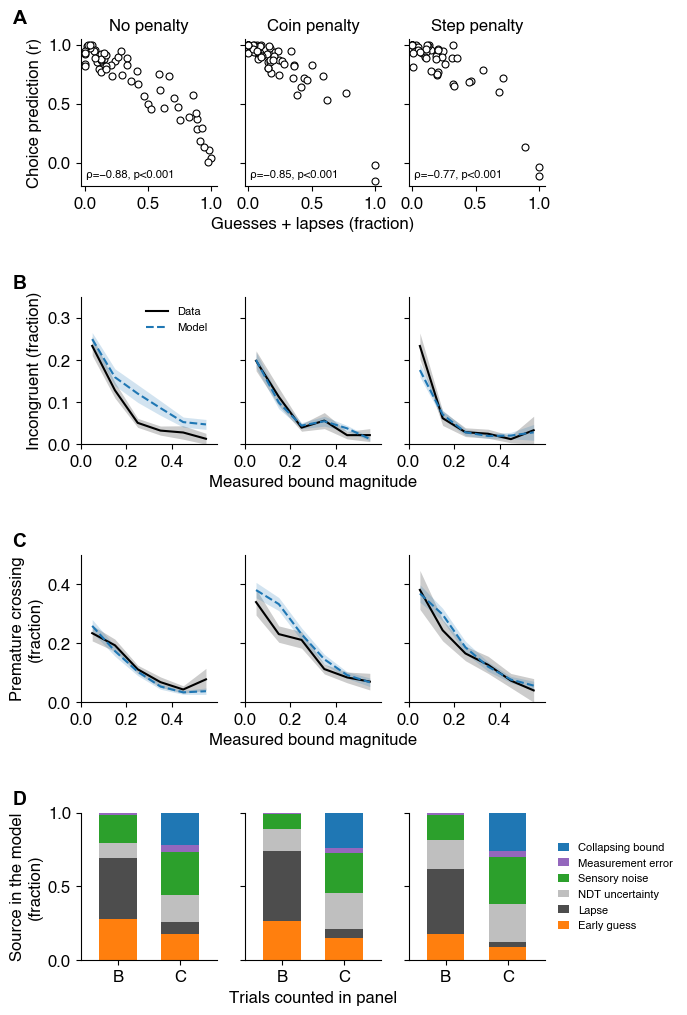

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S03.pdf (+ .png)


In [5]:
use_figure_style()
# Guesses and lapses in the colors of Figure 3F. Lapse is solid here: in 3F the hatching marks the lapse share of
# each bar, and here lapse is a category of its own (bound commits with a random choice).
SOURCE_STYLE = {'guess': {'color': GUESS_COLOR}, 'lapse': {'color': LAPSE_BAR['color']}, 'timing': {'color': '0.75'},
                'sensory noise': {'color': 'tab:green'}, 'measurement': {'color': 'tab:purple'},
                'collapsing bound': {'color': MODEL_COLOR}}
SOURCE_LABELS = {'guess': 'Early guess', 'measurement': 'Measurement error', 'timing': 'NDT uncertainty'}

fig = plt.figure(figsize=(17.6 * CM, 26 * CM))
gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.75, wspace=0.2, left=0.13, right=0.8, bottom=0.06, top=0.96)
ax_r = [fig.add_subplot(gs[0, i]) for i in range(3)]
ax_inc = [fig.add_subplot(gs[1, i]) for i in range(3)]
ax_pre = [fig.add_subplot(gs[2, i]) for i in range(3)]
ax_src = [fig.add_subplot(gs[3, i]) for i in range(3)]

for bi, b in enumerate(BLOCKS):
    ax = ax_r[bi]
    g = per_subject[per_subject.condition == b].dropna(subset=['r_choice', 'uninformed'])
    ax.plot(g.uninformed, g.r_choice, **SUBJECT_MARKER)
    ax.set_xlim(-0.03, 1.05)
    ax.set_ylim(-0.2, 1.05)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    rho, p = scipy.stats.spearmanr(g.uninformed, g.r_choice)
    ax.text(0.04, 0.05, f'{format_rho(rho)}, {format_p(p)}', transform=ax.transAxes, ha='left', va='bottom',
            fontsize=FS_INSET)
    if bi > 0:
        ax.set_yticklabels([])
    ax.set_title(BLOCK_TITLES[b])

    for ax, col, ylim in ((ax_inc[bi], 'incongruent', 0.35), (ax_pre[bi], 'premature_crossing', 0.5)):
        for t, color, ls, label in ((real, DATA_COLOR, '-', 'Data'), (model, MODEL_COLOR, '--', 'Model')):
            x, m, e = _binned(t[t.condition == b], col)
            ax.fill_between(x, m - e, m + e, color=color, alpha=0.2, lw=0)
            ax.plot(x, m, ls, color=color, lw=1.5, label=label)
        ax.set_xlim(0, MAX_BOUND)
        ax.set_ylim(0, ylim)
        ax.set_yticks(np.arange(0, ylim + 0.01, 0.1 if ylim < 0.4 else 0.2))
        ax.set_xticks([0, 0.2, 0.4])
        if bi > 0:
            ax.set_yticklabels([])

    ax = ax_src[bi]
    for xi, col in enumerate(('incongruent', 'premature_crossing')):
        bottom = 0.0
        for k in COMMIT_SOURCES:
            h = sources[col].loc[b, k]
            ax.bar(xi, h, bottom=bottom, **SOURCE_STYLE[k], width=0.6, lw=0)
            bottom += h
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['B', 'C'])   # the trials counted in rows B (incongruent) and C (premature crossing)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    if bi > 0:
        ax.set_yticklabels([])
ax_r[0].set_ylabel('Choice prediction (r)')
ax_inc[0].set_ylabel('Incongruent (fraction)')
ax_pre[0].set_ylabel('Premature crossing\n(fraction)')
ax_src[0].set_ylabel('Source in the model\n(fraction)')
ax_inc[0].legend(fontsize=FS_INSET, frameon=False, loc='upper right')
for k in reversed(COMMIT_SOURCES):
    ax_src[2].bar(0, 0, **SOURCE_STYLE[k], label=SOURCE_LABELS.get(k, k[0].upper() + k[1:]))
ax_src[2].legend(fontsize=FS_INSET, frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), handlelength=1)

add_row_xlabel(fig, ax_r, 'Guesses + lapses (fraction)')
add_row_xlabel(fig, ax_inc, 'Measured bound magnitude')
add_row_xlabel(fig, ax_pre, 'Measured bound magnitude')
add_row_xlabel(fig, ax_src, 'Trials counted in panel')
for ax in ax_r + ax_inc + ax_pre + ax_src:
    ax.spines[['top', 'right']].set_visible(False)
add_panel_label(ax_r[0], 'A', dx=-0.5, dy=1.2)
add_panel_label(ax_inc[0], 'B', dx=-0.5, dy=1.15)
add_panel_label(ax_pre[0], 'C', dx=-0.5, dy=1.15)
add_panel_label(ax_src[0], 'D', dx=-0.5, dy=1.15)

out = FIGURES_DIR / 'Figure03_S03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')